In [1]:
# Code imports
from lib.opt_types import *
from lib.utils import *
from lib.opt_types import *
from lib.utils import *


# Image inpainting with proximal methods - 30 points + 2 bonus points

Image in-painting consists of reconstructing the missing parts of an image from a given incomplete image.

By exploiting some prior knowledge on the image, it is possible to in-paint images that have a large portion of their pixels missing. In this part of the homework, we are going to study different methods to achieve this goal.

We consider a subsampled image $\mathbf{b} = \mathbf{P}_{\Omega} \mathbf{x}$, where $\mathbf{P}_{\Omega} \in \mathbb{R}^{n \times p}$ is an operator that selects only few, $n \ll p := m^2$, pixels from the vectorized image $\mathbf{x} \in \mathbb{R}^p$. Our goal is to reconstruct the original image $\mathbf{x}$.

### Prior knowledge

Image inpainting is impossible without having some prior knowledge on the structure of the true image $\mathbf{x}$. 

We will explore and compare the following prior assumptions we can make on the true image: 
>  **Assumption**: There exists a orthonormal basis $\mathbf{W} \in \mathbb{R}^{p\times p}$ such that $\mathbf{x}$ can be sparsely represented in that basis, i.e, $\mathbf{W} \mathbf{x}$ is a vector with few non-zero coefficients. Writing $\boldsymbol\alpha=\mathbf W\mathbf x$, we have $\mathbf x=\mathbf W^\top\boldsymbol\alpha$. We promote sparsity by penalizing $\|\boldsymbol\alpha\|_1$, a convex surrogate for the number of nonzero coefficients. We assume that this basis is known and corresponds to the _wavelet basis_. Under this assumption, the reconstruction problem corresponds to solving the following optimization problem:
$$
\min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2}_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
$$
where $\lambda_{\ell_1}$ is a coefficient we will need to choose.



# PART 1: Optimizing with an $\ell_1$ norm regularization

The optimization problem we are looking to solve have an objective function of the form:
$$
	 f(\mathbf{x}) + g(\mathbf{x}).
$$

These types of objectives are referred to as _composite objectives_ where one term, $f$, is smooth and differentiable and the other term $g$ is non-differentiable.

---

## Code structure:

Recall that we have been working with the `Function` type so far. We will augment this type to represent functions that are not differentiable:

- Given a `Function` `g` you can obtain a subgradient at a point `x` by calling `g.subgrad(x)`.

Moreover, since we are dealing with _composite_ problems with a an objective function that can be written `f + g`, we define the `CompositeFunction` type defined as
```python
@dataclass
class CompositeFunction:
    f: Function
    g: Function
```

The iterative schemes you will implement will receive a composite function that they can unpack as follows:

```python
def state_update(composite_function, state):
    f, g = composite_function

```

#### Question 1: (5 point)

A first approach to solve a non-smooth optimization problem can be to turn to subgradients. Review slide 42-44 of Lecture 6, and implement `SubG` with $\alpha_k = \frac{0.1}{\sqrt{k}}$, starting the counter at $k=1$.

In [2]:
@dataclass
class SubG_state(OptState):
    x_k: Vector
    k: int



In [3]:
def SubG_update(composite_function, state):
    f, g = composite_function
    x_k, k = state
    alpha_k = 0.1 / np.sqrt(k)
    subgrad_k = f.grad(x_k) + g.subgrad(x_k)
    x_next = x_k - alpha_k * subgrad_k
    return SubG_state(x_k=x_next, k=k + 1)

def SubG_initialize(composite_function, x_zero):
    return SubG_state(x_k=x_zero.copy(), k=1)


In [4]:
SubG = OptAlgorithm(name="SubG", init_state=SubG_initialize, state_update=SubG_update)

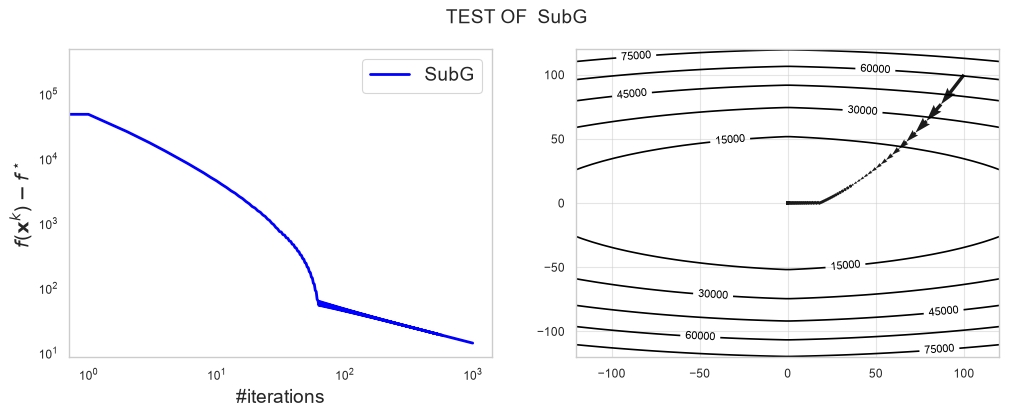

In [5]:
test_composite(SubG)


---

Another, more efficient approach, as we saw in Lecture 8, is to minimize such a function by using proximal gradient algorithms, provided that $g$ is _proximable_ (i.e., its proximal operator is efficient to evaluate). We recall the proximal operator of $g$ as the solution to the following convex problem:
$$
\mathrm{prox}_g(\mathbf{z}) := \mathrm{arg}\min_{\mathbf{y}\in\mathbb{R}^d}\{ g(\mathbf{y}) + \frac{1}{2}\Vert\mathbf{y} - \mathbf{z}\Vert_2^2\}.
$$

#### Question 2 (2 points)

Given $g_{\ell_1}: \mathbb{R}^p \rightarrow \mathbb{R}, \; g_{\ell_1}(\mathbf{x}) :=  \beta \|\mathbf{x}\|_1$ with $\beta\geq0$, show that its proximal function can be written as
    $$
    \mathrm{prox}_{\gamma g_{\ell_1}}(\mathbf{z}) = \max(|\mathbf{z}|-\beta \gamma,0) \circ \mathrm{sign}(\mathbf{z}), \; \text{for any }\mathbf{z} \in \mathbb{R}^p,\; \gamma \in \mathbb{R}_+
    $$
			where the operators $\max$, $\mathrm{sign}$ and $\lvert \cdot \lvert$ are applied coordinate-wise to the vector $\mathbf{z}$ and $\circ$ stands for $(\mathbf{x} \circ \mathbf{y})_i = x_i y_i$. Such a regularizer imposes sparsity on the solutions.


For $g_{\ell_1}(\mathbf{y}) = \beta\|\mathbf{y}\|_1$, the proximal operator of $\gamma g_{\ell_1}$ is defined by:
$$
\operatorname{prox}_{\gamma g_{\ell_1}}(\mathbf{z})
=\arg\min_{\mathbf{y}\in\mathbb R^p}
\left\{\gamma\beta\|\mathbf{y}\|_1+\frac12\|\mathbf{y}-\mathbf{z}\|_2^2\right\}.
$$
Set $\tau=\gamma\beta$, which is nonnegative because $\gamma,\beta\geq0$.
Expanding both norms gives:
$$
\gamma\beta\|\mathbf{y}\|_1+\frac12\|\mathbf{y}-\mathbf{z}\|_2^2
=\gamma\beta\sum_{i=1}^p |y_i|+\frac12\sum_{i=1}^p(y_i-z_i)^2=\sum_{i=1}^p\left(\tau |y_i|+\frac12(y_i-z_i)^2\right).
$$
Each coordinate can therefore be minimized independently.
For a single coordinate, we need to solve:
$$
\min_{u\in\mathbb R}\ \phi(u)
\quad\text{where}\quad
\phi(u)=\tau|u|+\frac12(u-z_i)^2.
$$
The quadratic term makes $\phi$ strictly convex, so its minimizer is unique.

Let $u>0$. Here $|u|=u$, so:
$$
\phi(u)=\tau u+\frac12(u-z_i)^2.
$$
and
$$
\phi'(u)=\tau+u-z_i.
$$
Setting the derivative to zero gives $u=z_i-\tau$. This is valid when $z_i>\tau$.

Let $u<0$. Here $|u|=-u$, so:
$$
\phi(u)=-\tau u+\frac12(u-z_i)^2.
$$
and
$$
\phi'(u)=-\tau+u-z_i.
$$
Setting the derivative to zero gives $u=z_i+\tau$. This is valid when $z_i<-\tau$.

Let $u=0$.
Since the absolute value function $h(u) = \vert{}u\vert{}$ is non-differentiable at $u=0$, we must use subgradients. By definition, a scalar $g$ is a subgradient of a convex function $h$ at $u_0$ if:
$$h(u) \geq h(u_0) + g(u - u_0) \quad \text{for all } u \in \mathbb{R}$$
For $h(u) = \vert{}u\vert{}$ at $u_0 = 0$, this condition becomes:
$$\vert{}u\vert{} \geq \vert{}0\vert{} + g(u - 0) \implies \vert{}u\vert{} \geq gu \quad \text{for all } u \in \mathbb{R}$$
This inequality holds if and only if $-1 \leq g \leq 1$. The _subdifferential_, denoted as $\partial h(u_0)$, is the set of all valid subgradients at that point.
Therefore:
$$\partial \vert{}0\vert{} = [-1, 1]$$
A point $u^\star$ is a globally optimal solution to a convex problem if and only if zero is contained in its subdifferential at that point:
$$0 \in \partial \phi(u^\star)$$
We apply this to our objective function $\phi(u) = \tau \vert{}u\vert{} + \frac{1}{2}(u - z_i)^2$. To evaluate $\partial \phi(0)$, we use Moreau-Rockafellar's theorem, which states that for convex functions, the subdifferential of a sum is the sum of the subdifferentials ($\partial(f+g) = \partial f + \partial g$).

Because the quadratic term is a differentiable convex function, its subdifferential contains only its gradient. Evaluating the sum at $u^\star = 0$ yields:
$$\partial \phi(0) = \tau \partial \vert{}0\vert{} + (0 - z_i) = \tau [-1, 1] - z_i$$
For $u=0$ to be the globally optimal solution, the necessary and sufficient condition requires:
$$0 \in \tau [-1, 1] - z_i$$
This is satisfied when:
$$-\tau \leq z_i \leq \tau$$

Combining the cases, the minimizing coordinate is
$$
u_i^\star=
\begin{cases}
z_i-\tau, & z_i>\tau,\\
0, & -\tau\leq z_i\leq\tau,\\
z_i+\tau, & z_i<-\tau.
\end{cases}
$$
Equivalently,
$$
u_i^\star
=\operatorname{sign}(z_i)\max(|z_i|-\tau,0).
$$
Applying this formula to every coordinate and substituting $\tau=\gamma\beta$ proves
$$
\boxed{
\operatorname{prox}_{\gamma g_{\ell_1}}(\mathbf{z})
=\max(|\mathbf{z}|-\beta\gamma,0)\circ\operatorname{sign}(\mathbf{z})
}.
$$
$$\blacksquare$$



#### Question 3 (1 point)
 Fill in the function `l1_prox` with the proximal operator of $g_{\ell_1}$.

In [6]:
def l1_prox(gamma, z, beta):
    return np.sign(z) * np.maximum(np.abs(z) - gamma * beta, 0)


#### Question 4 (4 points)

From here on, in order to speed-up the convergence of the optimization, let's assume that the function $f$ has been made to be $\mu$-strongly convex by the addition of an $\ell_2$ regularization term to the function $f$, while the $\ell_1$ term, $g$, has remained unchanged. As such, we must now utilize the strong-convexity versions of the composite optimization algorithms.

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{ISTA}_\mu$. In the provided quadratic test, $\beta=30$. Use `g.prox(alpha, z)` to apply the proximal operator of the supplied regularizer, including its weight.

In [7]:
@dataclass
class ISTA_state(OptState):
    x_k: Vector


In [8]:
def ISTA_update(composite_function, state):
    f, g = composite_function
    (x_k,) = state
    alpha = 2.0 / (f.lips_grad + f.strng_cvx)
    z = x_k - alpha * f.grad(x_k)
    x_next = g.prox(alpha, z)
    return ISTA_state(x_k=x_next)

def ISTA_initialize(composite_function, x_zero):
    return ISTA_state(x_k=x_zero.copy())


In [9]:
ISTA = OptAlgorithm(name="ISTA", init_state=ISTA_initialize, state_update=ISTA_update)

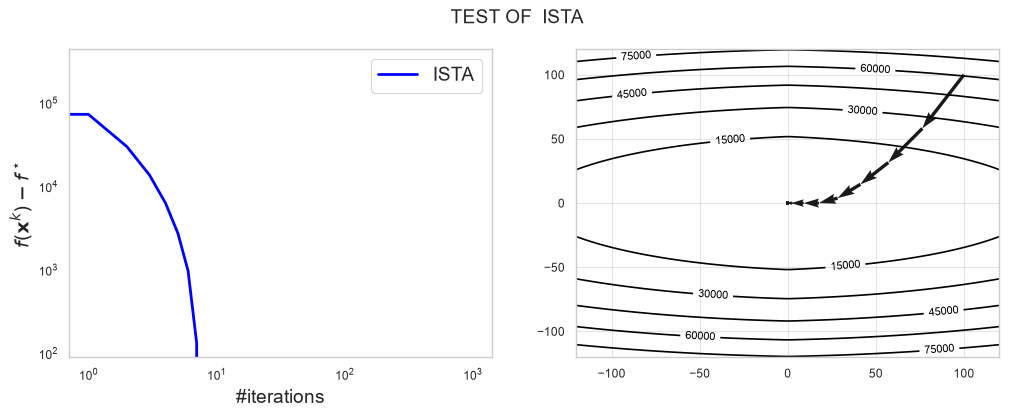

In [10]:
test_composite(ISTA, prox=l1_prox)


#### Question 5  (7 points)

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{FISTA}_\mu$.

In [11]:
@dataclass
class FISTA_state(OptState):
    x_k: Vector
    y_k: Vector
    beta_k: float



In [12]:
import numpy

def FISTA_update(composite_function, state):
    f, g = composite_function
    x_k, y_k, beta_k = state
    alpha = 1.0 / f.lips_grad
    x_next = g.prox(alpha, y_k - alpha * f.grad(y_k))
    y_next = x_next + beta_k * (x_next - x_k)
    return FISTA_state(x_k=x_next, y_k=y_next, beta_k=beta_k)

def FISTA_initialize(composite_function, x_zero):
    f, _ = composite_function
    beta_k = (np.sqrt(f.lips_grad) - np.sqrt(f.strng_cvx)) / (np.sqrt(f.lips_grad) + np.sqrt(f.strng_cvx))
    x_zero = x_zero.copy()
    return FISTA_state(x_k=x_zero, y_k=x_zero.copy(), beta_k=beta_k)


In [13]:
FISTA = OptAlgorithm(name="FISTA", init_state=FISTA_initialize, state_update=FISTA_update)


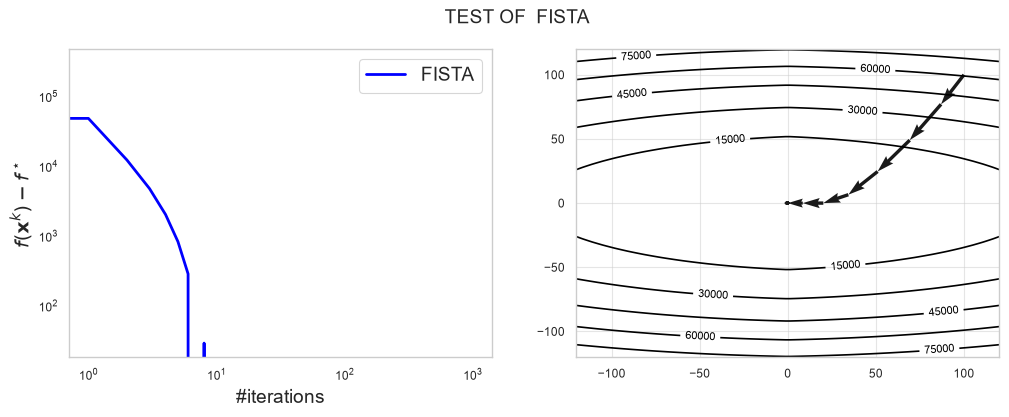

In [14]:
test_composite(FISTA, prox=l1_prox)


#### Question 6  (2 points)

Compare the convergence rates of the three methods and analyze whether the observed results align with their theoretical bounds.

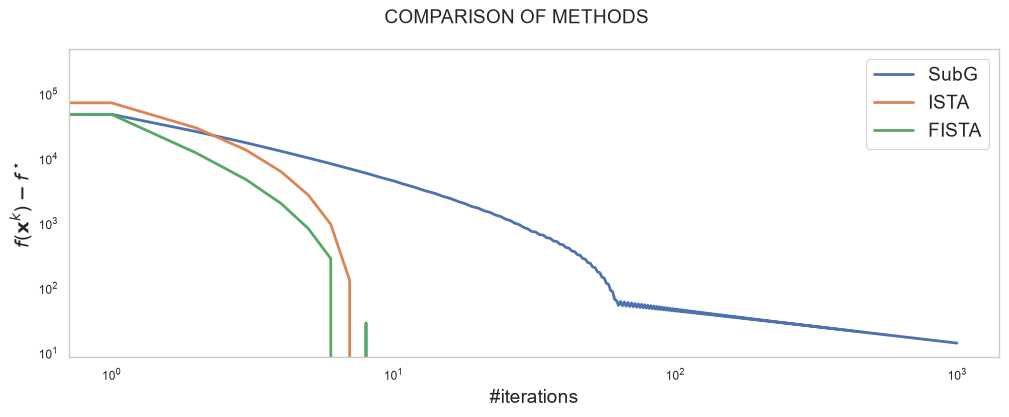

In [15]:
list_of_methods = [SubG, ISTA, FISTA]
compare_composite(list_of_methods, prox=l1_prox)



FISTA converges fastest in the observed test, followed by ISTA, while the subgradient method converges slowest. This is consistent with the theory: for ISTA and FISTA, the smooth term
$f$ is $\mu$-strongly convex and has an $L_f$-Lipschitz gradient, allowing them to achieve a global linear convergence rate with FISTA providing faster theoretical acceleration.

The subgradient method uses a step size proportional to $1/\sqrt{k}$ and has a slower $\mathcal{O}(1/\sqrt{k})$ guarantee for the best objective value seen so far. The plot may show the current iterate instead, so its curve need not follow that guarantee point by point.


# Part 2: Application


We have now implemented multiple methods that can solve composite optimization problems. We will now apply them to an image inpainting problem.


Take a natural image, or better a picture of you, and place it in the same directory as this notebook.

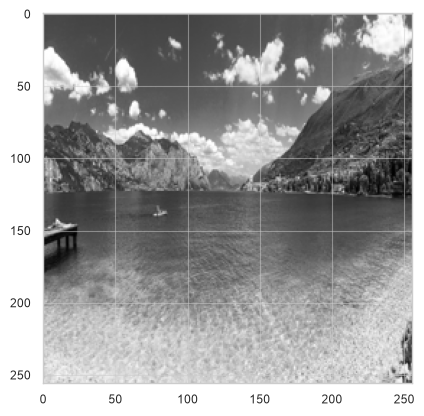

In [16]:
from lib.inpainting import *
# Let's load a landscape image
image = load("Landscape_photo.jpg")


With this image in hand, let us subsample it and try to reconstruct the original.

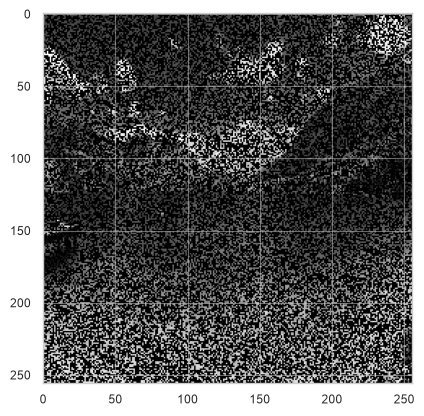

In [17]:
subsampled = show_subsampled(image)

For the rest of the questions, to ensure the function is 
$\mu$-strongly convex, we need to add an $\ell_2$ regularization term to it. As a result, we change the definition of $f_{\ell_1}(\mathbf{\alpha})$ as follows:
$$
    f_{\ell_1}(\mathbf{\alpha}) = \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 
    $$

and the composite function becomes:
 $$
    \min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 }_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
    $$

By adding this regularization, we ensure better properties for optimization, making the solution more stable and well-behaved.

In the following cells we will define the optimization problems we need to solve to perform the reconstruction.

- We provide you with a function `P` that acts like the matrix $\mathbf{P}_{\Omega}$. That is, given a vector `x`, it returns a subsampled vector `P(x)` that corresponds to $\mathbf{P}_{\Omega} \mathbf{x}$. We also give you `P_T` which acts like $\mathbf{P}^\top$.
- We provide you with a function `W` and `W_T` that act like the matrix $\mathbf{W}$ and $\mathbf{W^\top}$ respectively. That is, for a vector `x`, `W(x)` and `W_T(x)` return $\mathbf{W}\mathbf{x}$ and $\mathbf{W^\top}\mathbf{x}$ respectively.

__(a)__ (1 point) Using these provided functions, define the observed variable `b` in the cell below.

In [18]:
from lib.inpainting import P, P_T, W, W_T
# Flatten the image and keep only the sampled pixel values.
x = image.reshape(-1)
b = P(x)

__(b)__ (1 point) Now define the function `f_l1` as described earlier in the problem text.

In [19]:
mu = 1e-4
def f_l1(alpha):
    residual = P(W_T(alpha)) - b
    return 0.5 * np.dot(residual, residual) + 0.5 * mu * np.dot(alpha, alpha)

__(c)__ (1 point) Write the gradient of $f_{\ell_1}(\mathbf{\alpha})$.

In [20]:
def grad_f_l1(alpha):
    residual = P(W_T(alpha)) - b
    return W(P_T(residual)) + mu * alpha

__(d)__ (1 points) Find the Lipschitz constant of $\nabla_\mathbf{\alpha} f_{\ell_1}(\mathbf{\alpha})$ analytically and fill it in the cell below. 

Let
$$ f_{\ell_1}(\boldsymbol\alpha) = \frac{1}{2}\|\mathbf{P}_{\Omega} \mathbf{W}^\top\boldsymbol\alpha - \mathbf{b}\|_2^2 + \frac{\mu}{2}\|\boldsymbol\alpha\|_2^2, $$
We define:
$$ \mathbf{r}(\boldsymbol\alpha) = \mathbf{P}_{\Omega} \mathbf{W}^\top\boldsymbol\alpha - \mathbf{b}. $$
By the chain rule:
$$ \nabla_\alpha f_{\ell_1}(\boldsymbol\alpha) = \mathbf{W} \mathbf{P}_{\Omega}^\top \mathbf{r}(\boldsymbol\alpha) + \mu\boldsymbol\alpha. $$

For any two coefficient vectors $\boldsymbol\alpha, \widetilde{\boldsymbol\alpha}$, the residual difference is:
$$ \mathbf{r}(\boldsymbol\alpha) - \mathbf{r}(\widetilde{\boldsymbol\alpha}) =\mathbf{P}_{\Omega} \mathbf{W}^\top\boldsymbol\alpha - \mathbf{b}-(\mathbf{P}_{\Omega} \mathbf{W}^\top\widetilde{\boldsymbol\alpha} - \mathbf{b}) =\mathbf{P}_{\Omega} \mathbf{W}^\top(\boldsymbol\alpha - \widetilde{\boldsymbol\alpha}). $$
Therefore:
$$ \begin{aligned} \nabla f_{\ell_1}(\boldsymbol\alpha) - \nabla f_{\ell_1}(\widetilde{\boldsymbol\alpha}) &=\mathbf{W} \mathbf{P}_{\Omega}^\top \mathbf{r}(\boldsymbol\alpha) + \mu\boldsymbol\alpha. -(\mathbf{W} \mathbf{P}_{\Omega}^\top \mathbf{r}(\widetilde{\boldsymbol\alpha}) + \mu\widetilde{\boldsymbol\alpha} )= \left(\mathbf{W} \mathbf{P}_{\Omega}^\top \mathbf{P}_{\Omega} \mathbf{W}^\top + \mu \mathbf{I}\right) (\boldsymbol\alpha - \widetilde{\boldsymbol\alpha}). \end{aligned} $$

Applying $\Vert{}\mathbf{A}\mathbf{x}\Vert{}_2 \le \Vert{}\mathbf{A}\Vert{}_2 \Vert{}\mathbf{x}\Vert{}_2$) we obtain:
$$\Vert{}\nabla f_{\ell_1}(\boldsymbol\alpha) - \nabla f_{\ell_1}(\widetilde{\boldsymbol\alpha})\Vert{}_2 \le \Vert{}\mathbf{W} \mathbf{P}_{\Omega}^\top \mathbf{P}_{\Omega} \mathbf{W}^\top + \mu \mathbf{I}\Vert{}_2 \Vert{}\boldsymbol\alpha - \widetilde{\boldsymbol\alpha}\Vert{}_2$$
We then apply the triangle inequality:
$$\begin{aligned}
|\nabla f_{\ell_1}(\boldsymbol\alpha) - \nabla f_{\ell_1}(\widetilde{\boldsymbol\alpha})|_2 &\le \left( |\mathbf{W} \mathbf{P}_{\Omega}^\top \mathbf{P}_{\Omega} \mathbf{W}^\top|_2 + |\mu \mathbf{I}|_2 \right) |\boldsymbol\alpha - \widetilde{\boldsymbol\alpha}|_2
\end{aligned}$$
$$\left( |\mathbf{W} \mathbf{P}_{\Omega}^\top \mathbf{P}_{\Omega} \mathbf{W}^\top|_2 + |\mu \mathbf{I}|_2 \right) |\boldsymbol\alpha - \widetilde{\boldsymbol\alpha}|_2\le \left( |\mathbf{W}|_2 |\mathbf{P}_{\Omega}^\top|_2 |\mathbf{P}_{\Omega}|_2 |\mathbf{W}^\top|_2 + \mu \right) |\boldsymbol\alpha - \widetilde{\boldsymbol\alpha}|_2$$

Since $\mathbf{W}$ is orthonormal it holds that $\|\mathbf{W}\|_2 = \|\mathbf{W}^\top\|_2 = 1$. Since $\mathbf{P}_{\Omega}$ selects pixels it holds that $\|\mathbf{P}_{\Omega}\|_2 = \|\mathbf{P}_{\Omega}^\top\|_2 = 1$.
Thus:
$$ \|\nabla f_{\ell_1}(\boldsymbol\alpha) - \nabla f_{\ell_1}(\widetilde{\boldsymbol\alpha})\|_2 \le (1 + \mu)\|\boldsymbol\alpha - \widetilde{\boldsymbol\alpha}\|_2. $$

Hence the gradient is Lipschitz continuous with constant:
$$L_{\nabla f_{\ell_1}} = 1 + \mu. $$

In [21]:
lips_grad_f_l1 = 1.0 + mu

We have all the necessary ingredients to define the smooth part of our composite objective:

In [22]:
f_l1 = Function(f=f_l1, grad=grad_f_l1, lips_grad=lips_grad_f_l1, strng_cvx=mu)

For the non-smooth term, `l1` represents the unweighted $\ell_1$ norm. `Regularizer` applies the weight `lmda` to both the function value and its proximal operator, reusing `l1_prox` with $\beta=1$:

In [23]:
l1 = Function(
    f=lambda x: np.sum(np.abs(x), axis=0),
    prox=lambda gamma, z: l1_prox(gamma, z, beta=1))
g_l1 = Regularizer(l1)


In [24]:
composite_objective = CompositeFunction(f=f_l1, g=g_l1)

With the objective defined, we provide you with a function with the following signature:
```python
solve_composite(method: OptAlgorithm, composite_objective: CompositeFunction, lmda: float, max_iterations: int) -> Vector
```

In other words, the function takes an optimization algorithm `method`, a CompositeFunction `composite_objective`, a regularization parameter `lmda` and a number of iterations `max_iterations` and returns a vector which is the last iterate given by the `method`.



In [25]:
from lib.inpainting import solve_composite

__(e)__ (5 points) Using `solve_composite` reconstruct the subsampled image. Recall that the composite problem solves for $\mathbf{\alpha}$ so you need to convert the output back to an image and visualize it.

Select a reasonable value for `lmda`.

**Bonus (2 points).** Using `solve_composite` and the `PSNR` metric, find the best value for `lmda`.

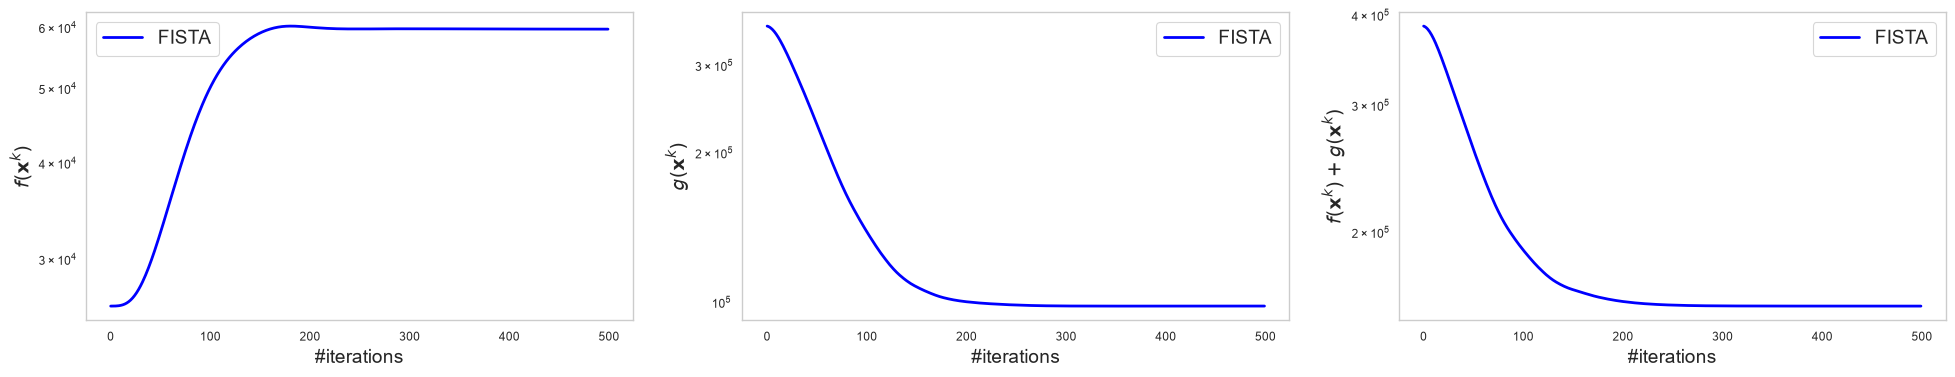

In [26]:
# A reasonable choice might be setting lmda=0.1
lmda = 0.1
out = solve_composite(FISTA, composite_objective, lmda, max_iterations=500)
flat_image_out = W_T(out)
# Reconstruct the image using the chosen lambda value.
image_out = flat_image_out.reshape(image.shape)

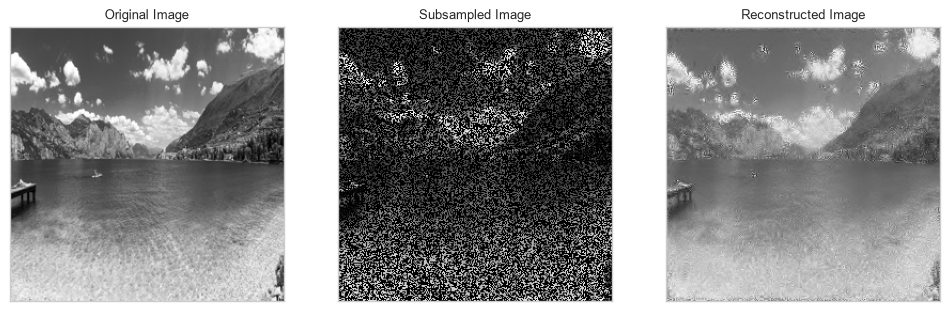

In [27]:
# Compare the original, subsampled, and reconstructed images.
show(true = image, subsampled=subsampled, estimated=image_out)

#### Bonus point (choice of the regularization weight)
We use a grid search: choose a fixed set of candidate values for $\lambda$, solve the reconstruction problem for each value, and compare the resulting images using PSNR. The code tests 30 logarithmically spaced candidates from $10^{-3}$ to $10^3$. Logarithmic spacing explores values across several scales, since the useful regularization weight may differ by multiplicative factors.
For this experiment, the original image is available, so we can compute each candidate reconstruction's PSNR against it. The selected value is the one with the highest PSNR among the 30 candidates; it is not necessarily the exact global optimum. If the best candidate is at either endpoint of the grid, extend the range and search again.

Best lambda: 5.298316906283707 PSNR: 23.63728161891849


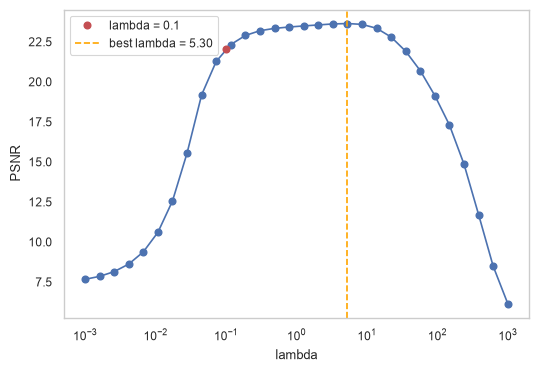

In [32]:
lambda_candidates = np.logspace(-3, 3, 30)
psnr_results = []
def PSNR(reference, estimate):
    reference = reference.astype(float)
    estimate = estimate.astype(float)

    mse = np.mean((reference - estimate) ** 2)
    if mse == 0:
        return float("inf")

    peak = float(np.max(reference))
    return 10.0 * np.log10((peak ** 2) / mse)

# Compare reconstruction quality across candidate regularization weights.
for candidate in lambda_candidates:
    alpha_candidate = solve_composite(
        FISTA, composite_objective, float(candidate), max_iterations=500
    )
    image_candidate = W_T(alpha_candidate).reshape(image.shape)
    psnr_results.append(PSNR(image, image_candidate))
    plt.close("all")

# Higher PSNR indicates a closer reconstruction to the reference image.
best_index = int(np.argmax(psnr_results))
best_lmda = float(lambda_candidates[best_index])
best_psnr = float(psnr_results[best_index])

print("Best lambda:", best_lmda, "PSNR:", best_psnr)

# PSNR as a function of lambda
plt.figure(figsize=(6, 4))
plt.semilogx(lambda_candidates, psnr_results, "o-")
plt.plot(0.1, PSNR(image, image_out), "ro", label="lambda = 0.1")
plt.axvline(best_lmda, color="orange", linestyle="--", label="best lambda = %.2f" % best_lmda)
plt.xlabel("lambda")
plt.ylabel("PSNR")
plt.legend()
plt.grid()
plt.show()

# The PSNR increases up to the selected lambda and decreases afterwards, so on this grid supporting the choice empirically.

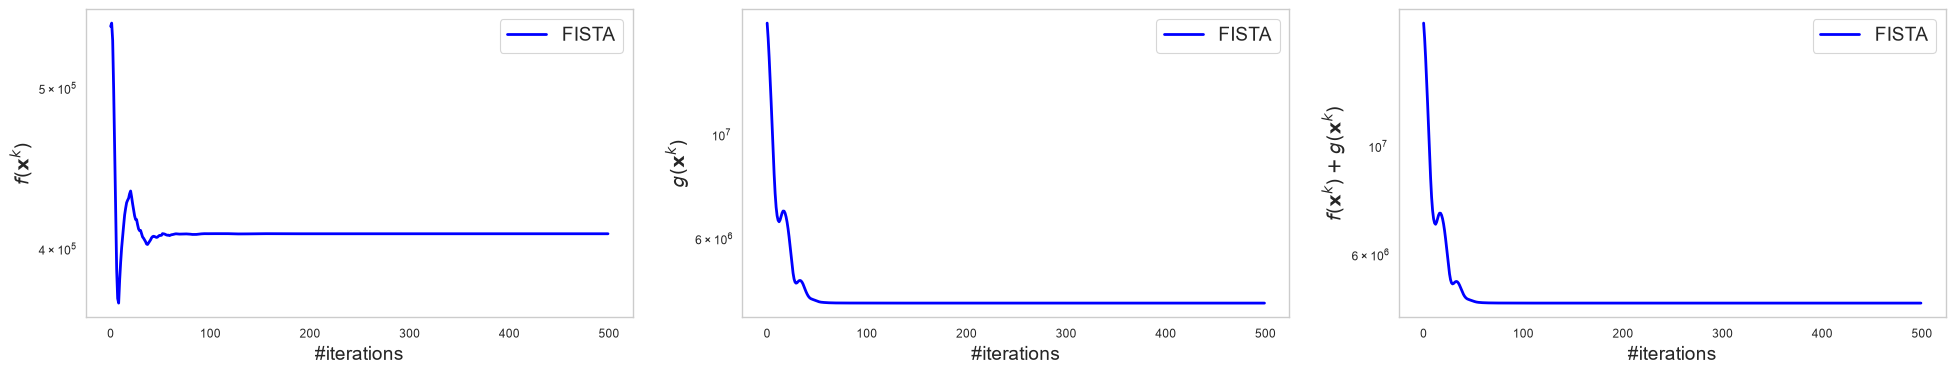

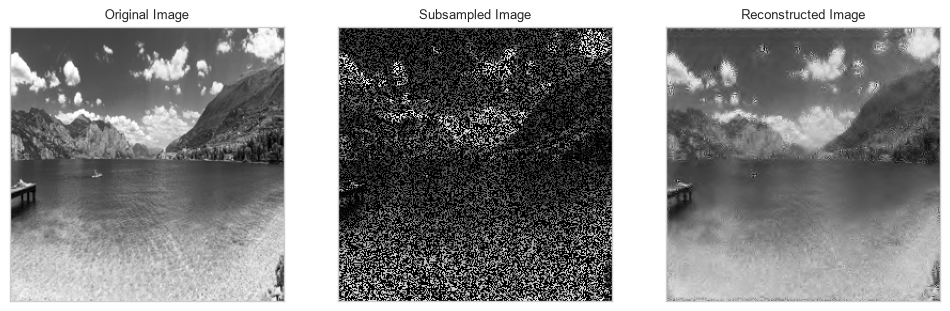

In [29]:
# Refit using the best lambda found by the grid search
out_best = solve_composite(
    FISTA, composite_objective, best_lmda, max_iterations=500
)
image_best = W_T(out_best).reshape(image.shape)

# Compare the original, subsampled, and reconstructed images for the selected best lambda value.
show(true=image, subsampled=subsampled, estimated=image_best)